In [ ]:
import urllib.request
import os

# Dictionary containing sample image URLs and their target filenames
images = {
    "focus_near.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/left01.jpg",
    "focus_far.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/left02.jpg",
    "otter1.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/left03.jpg",
    "otter2.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/left04.jpg"
}

print("Downloading sample images for the tasks...")
for filename, url in images.items():
    try:
        urllib.request.urlretrieve(url, filename)
        print(f"✓ Successfully downloaded and saved {filename}")
    except Exception as e:
        print(f"✗ Failed to download {filename} from {url}: {e}")

print("\nAll set! You can now run the rest of the cells.")

✓ Successfully downloaded and saved focus_near.jpg
✓ Successfully downloaded and saved focus_far.jpg
✓ Successfully downloaded and saved otter1.jpg
✓ Successfully downloaded and saved otter2.jpg

All set! You can now run the rest of the cells.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
# 1. Read the two images captured at different focus settings
img1 = cv2.imread("focus_near.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("focus_far.jpg", cv2.IMREAD_GRAYSCALE)

In [ ]:
# 2. Check that both images were loaded
if img1 is None or img2 is None:
    raise FileNotFoundError("Check the image names and file paths.")

In [ ]:
# 3. Make both images the same size
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))


In [ ]:
# 4. Apply a small Gaussian blur to reduce sensor noise
img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)


In [ ]:
# 5. Calculate the Laplacian response
lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)


In [ ]:
# 6. Estimate local focus using squared Laplacian
kernel = (15, 15)
focus1 = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
focus2 = cv2.GaussianBlur(lap2 ** 2, kernel, 0)

In [ ]:
# 7. Compare the focus measures
eps = 1e-8
focus_diff = (focus1 - focus2) / (focus1 + focus2 + eps)


In [ ]:
# 8. Convert the relative focus difference into a displayable map
depth_map = cv2.normalize(focus_diff, None, 0, 255,
cv2.NORM_MINMAX).astype(np.uint8)

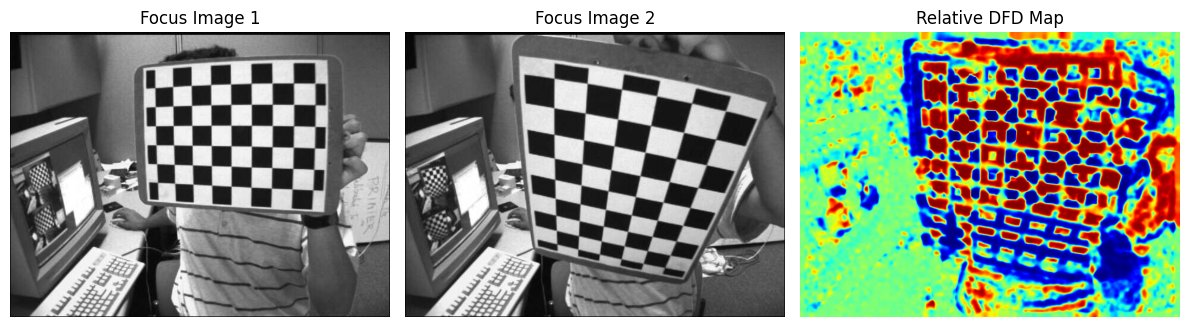

True

In [ ]:
# 9. Display the input images and the DFD result
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img1, cmap="gray")
plt.title("Focus Image 1")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(img2, cmap="gray")
plt.title("Focus Image 2")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(depth_map, cmap= "jet")
plt.title("Relative DFD Map")
plt.axis("off")
plt.tight_layout()
plt.show()
# 10. Save the result
cv2.imwrite("dfd_relative_depth.png", depth_map)

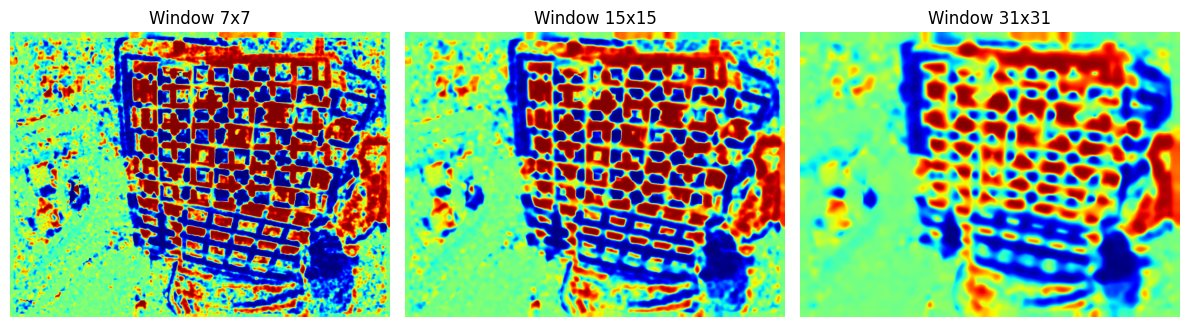

In [ ]:
#TASK 1: Compare different window sizes

plt.figure(figsize=(12, 4))

for i, k in enumerate([7, 15, 31]):
    f1 = cv2.GaussianBlur(lap1**2, (k, k), 0)
    f2 = cv2.GaussianBlur(lap2**2, (k, k), 0)

    diff = (f1 - f2) / (f1 + f2 + 1e-8)
    result = cv2.normalize(diff, None, 0, 255,
                           cv2.NORM_MINMAX).astype(np.uint8)

    plt.subplot(1, 3, i + 1)
    plt.imshow(result, cmap="jet")
    plt.title(f"Window {k}x{k}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#TASK 2: Compare squared Laplacian and Laplacian variance

def laplacian_variance(img):
    lap = cv2.Laplacian(
        cv2.GaussianBlur(img, (3, 3), 0).astype(np.float64),
        cv2.CV_64F
    )
    mean = cv2.GaussianBlur(lap, (15, 15), 0)
    mean_sq = cv2.GaussianBlur(lap**2, (15, 15), 0)
    return np.maximum(mean_sq - mean**2, 0)

# Existing squared-Laplacian focus measures
sq1 = focus1
sq2 = focus2

# New variance-based focus measures
var1 = laplacian_variance(img1)
var2 = laplacian_variance(img2)

def create_dfd_map(a, b):
    diff = (a - b) / (a + b + 1e-8)
    return cv2.normalize(diff, None, 0, 255,
                         cv2.NORM_MINMAX).astype(np.uint8)

map_squared = create_dfd_map(sq1, sq2)
map_variance = create_dfd_map(var1, var2)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(map_squared, cmap="jet")
plt.title("Squared Laplacian")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(map_variance, cmap="jet")
plt.title("Laplacian Variance")
plt.axis("off")

plt.tight_layout()
plt.show()


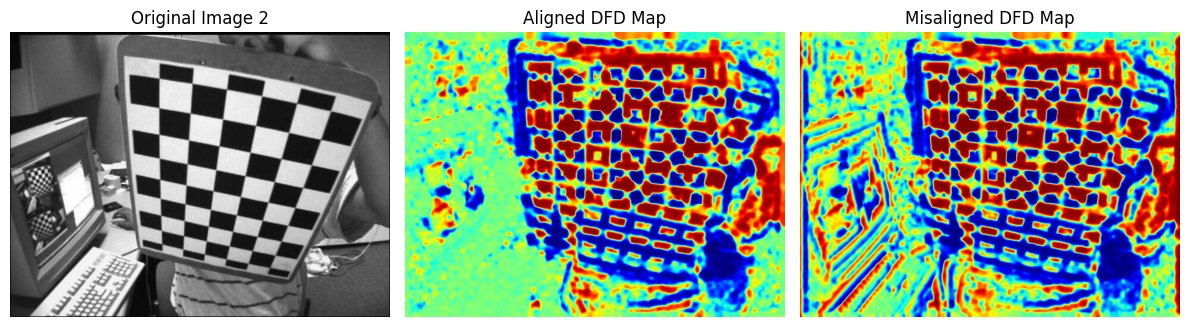

In [ ]:
#TASK 3: Observe the effect of image misalignment

h, w = img2.shape

M = np.float32([
    [1, 0, 5],
    [0, 1, 0]
])

shifted_img2 = cv2.warpAffine(img2, M, (w, h))

def get_focus_measure(img):
    smooth = cv2.GaussianBlur(img, (3, 3), 0)
    lap = cv2.Laplacian(smooth, cv2.CV_64F)
    return cv2.GaussianBlur(lap**2, (15, 15), 0)

f1 = get_focus_measure(img1)
f2_aligned = get_focus_measure(img2)
f2_shifted = get_focus_measure(shifted_img2)

aligned_map = create_dfd_map(f1, f2_aligned)
shifted_map = create_dfd_map(f1, f2_shifted)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img2, cmap="gray")
plt.title("Original Image 2")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(aligned_map, cmap="jet")
plt.title("Aligned DFD Map")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(shifted_map, cmap="jet")
plt.title("Misaligned DFD Map")
plt.axis("off")

plt.tight_layout()
plt.show()


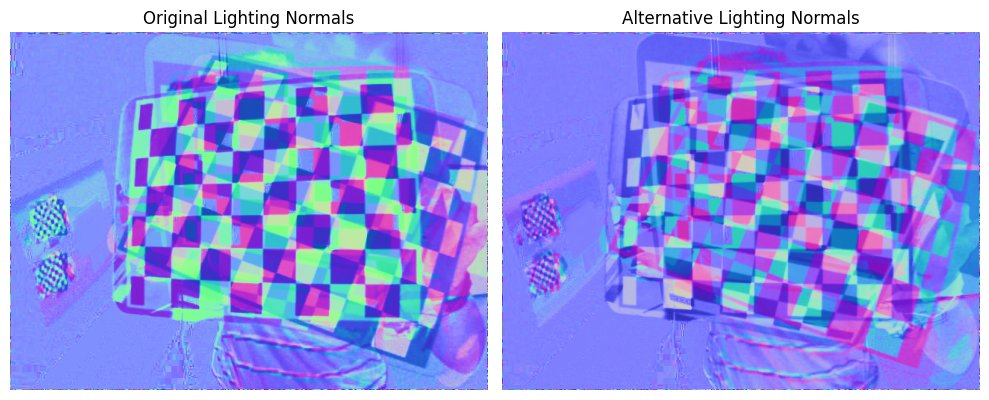

In [ ]:
#TASK 4: Compare different lighting directions

files = ["focus_far.jpg", "focus_near.jpg", "otter1.jpg", "otter2.jpg"]
light_images = []

for f in files:
    im = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    if im is None:
        raise FileNotFoundError(f"Cannot find {f}")
    light_images.append(im.astype(np.float64) / 255.0)

# Ensure all images have identical dimensions
base_h, base_w = light_images[0].shape
light_images = [
    cv2.resize(im, (base_w, base_h)) for im in light_images
]
I = np.stack(light_images)

L_original = np.array([
    [0, 0, 1],
    [0.6, 0, 0.8],
    [-0.6, 0, 0.8],
    [0, 0.6, 0.8]
], dtype=float)

L_alternative = np.array([
    [0.4, 0.4, 0.82],
    [-0.4, 0.4, 0.82],
    [0.4, -0.4, 0.82],
    [-0.4, -0.4, 0.82]
], dtype=float)

def calculate_normals(I, L):
    L = L / np.linalg.norm(L, axis=1, keepdims=True)
    G = np.linalg.pinv(L) @ I.reshape(I.shape[0], -1)
    albedo = np.linalg.norm(G, axis=0)
    N = G / (albedo[None, :] + 1e-8)
    return N.reshape(3, I.shape[1], I.shape[2])

N1 = calculate_normals(I, L_original)
N2 = calculate_normals(I, L_alternative)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.clip(np.moveaxis((N1 + 1) / 2, 0, -1), 0, 1))
plt.title("Original Lighting Normals")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.clip(np.moveaxis((N2 + 1) / 2, 0, -1), 0, 1))
plt.title("Alternative Lighting Normals")
plt.axis("off")

plt.tight_layout()
plt.show()


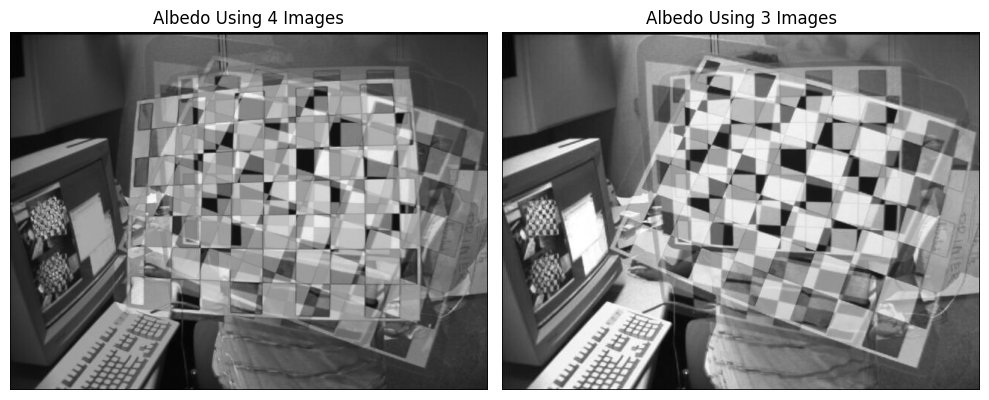

In [ ]:
#TASK 5: Compare three-image and four-image Photometric Stereo

def calculate_albedo(I, L):
    L = L / np.linalg.norm(L, axis=1, keepdims=True)
    G = np.linalg.pinv(L) @ I.reshape(I.shape[0], -1)
    return np.linalg.norm(G, axis=0).reshape(I.shape[1], I.shape[2])

albedo4 = calculate_albedo(I, L_original)
albedo3 = calculate_albedo(I[:3], L_original[:3])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(albedo4, cmap="gray")
plt.title("Albedo Using 4 Images")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(albedo3, cmap="gray")
plt.title("Albedo Using 3 Images")
plt.axis("off")

plt.tight_layout()
plt.show()


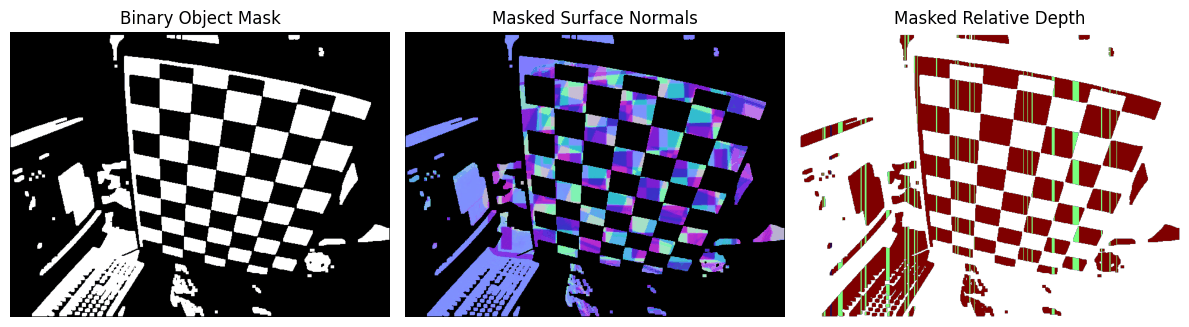

In [ ]:
#TASK 6: Mask background pixels

first_image = cv2.imread("focus_far.jpg", cv2.IMREAD_GRAYSCALE)

# Create a binary mask using Otsu thresholding
_, mask = cv2.threshold(
    first_image, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# If the object is darker than the background, uncomment:
# mask = cv2.bitwise_not(mask)

mask = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN,
    np.ones((5, 5), np.uint8)
)
object_mask = mask > 0

# Estimate normals using the original lighting matrix
N = calculate_normals(I, L_original)

nx, ny, nz = N
p = -nx / (nz + 1e-8)
q = -ny / (nz + 1e-8)

# Integrate gradients to estimate relative depth
depth = np.zeros((base_h, base_w), dtype=np.float64)

for y in range(base_h):
    depth[y, 1:] = np.cumsum(p[y, :-1])

for x in range(base_w):
    depth[1:, x] += np.cumsum(q[:-1, x])

# Hide background values for visualization
masked_depth = np.ma.masked_where(~object_mask, depth)
normal_rgb = np.clip(np.moveaxis((N + 1) / 2, 0, -1), 0, 1)
normal_rgb[~object_mask] = 0

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Binary Object Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(normal_rgb)
plt.title("Masked Surface Normals")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(masked_depth, cmap="jet")
plt.title("Masked Relative Depth")
plt.axis("off")

plt.tight_layout()
plt.show()


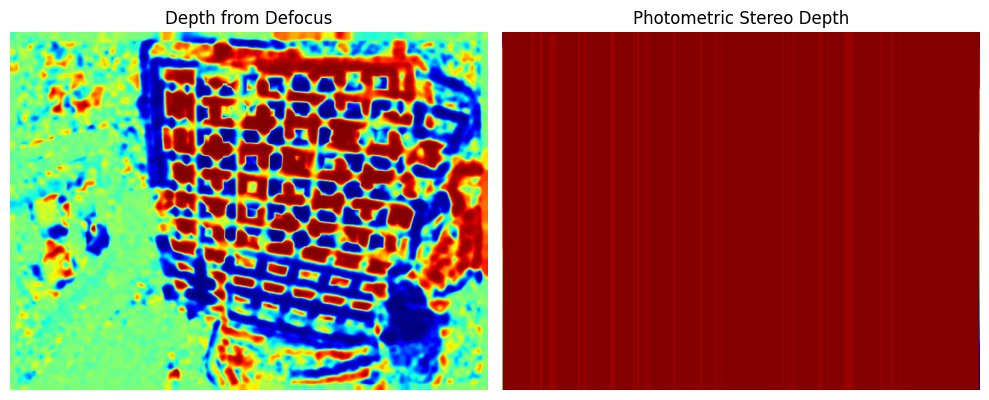

In [ ]:

# TASK 7: Final comparison of DFD and Photometric Stereo

# DFD map from your existing experiment
dfd_result = depth_map

# Photometric Stereo surface normals
N = calculate_normals(I, L_original)

nx, ny, nz = N
p = -nx / (nz + 1e-8)
q = -ny / (nz + 1e-8)

# Relative depth reconstruction
depth_ps = np.zeros((base_h, base_w), dtype=np.float64)

for y in range(base_h):
    depth_ps[y, 1:] = np.cumsum(p[y, :-1])

for x in range(base_w):
    depth_ps[1:, x] += np.cumsum(q[:-1, x])

depth_ps_vis = cv2.normalize(
    depth_ps, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Display the two results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(dfd_result, cmap="jet")
plt.title("Depth from Defocus")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_ps_vis, cmap="jet")
plt.title("Photometric Stereo Depth")
plt.axis("off")

plt.tight_layout()
plt.show()


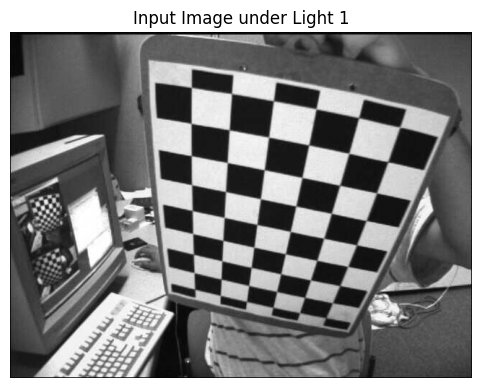

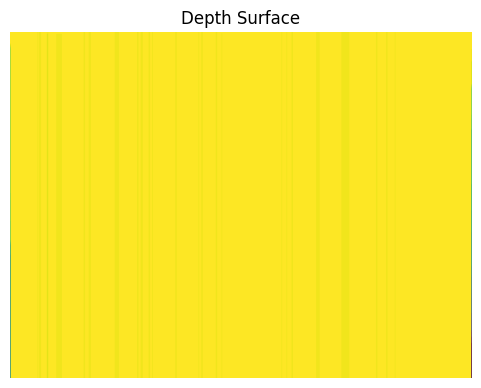

In [ ]:
# Figure 4 and Figure 8 for the practical (main Photometric Stereo program)
import os, urllib.request, cv2, numpy as np, matplotlib.pyplot as plt
base = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/"
src = {"focus_near.jpg": "left01.jpg", "focus_far.jpg": "left02.jpg", "otter1.jpg": "left03.jpg", "otter2.jpg": "left04.jpg"}
_ = [urllib.request.urlretrieve(base + v, k) for k, v in src.items() if not os.path.exists(k)]
files = ["focus_far.jpg", "focus_near.jpg", "otter1.jpg", "otter2.jpg"]
imgs = [cv2.imread(f, cv2.IMREAD_GRAYSCALE).astype(np.float64) / 255.0 for f in files]
I = np.stack(imgs, axis=0)
L = np.array([[0.0, 0.0, 1.0], [0.6, 0.0, 0.8], [-0.6, 0.0, 0.8], [0.0, 0.6, 0.8]])
L = L / np.linalg.norm(L, axis=1, keepdims=True)
m, h, w = I.shape
G = np.linalg.pinv(L) @ I.reshape(m, -1)
albedo = np.linalg.norm(G, axis=0)
normals = G / (albedo[None, :] + 1e-8)
nx, ny, nz = [normals[k].reshape(h, w) for k in range(3)]
p = -nx / (nz + 1e-8)
q = -ny / (nz + 1e-8)
depth = np.zeros((h, w))
depth[:, 1:] = np.cumsum(p[:, :-1], axis=1)
depth[1:, :] += np.cumsum(q[:-1, :], axis=0)
plt.figure(figsize=(6, 4.5)); plt.imshow(imgs[0], cmap="gray"); plt.title("Input Image under Light 1"); plt.axis("off"); plt.show()
plt.figure(figsize=(6, 4.5)); plt.imshow(depth, cmap="viridis"); plt.title("Depth Surface"); plt.axis("off"); plt.show()